    Step 1: Data Understanding & Preprocessing
    •	Load and explore the dataset.
    •	Check for missing values and handle them.
    •	Convert categorical variables (Fuel_Type, Mileage, Airbags) into numerical format.


In [1]:
import pandas as pd
import numpy as np
path=r"https://raw.githubusercontent.com/rushidhende06-pixel/Datasets/refs/heads/main/car_price_prediction.csv"
df=pd.read_csv(path)
df.head()


,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [2]:
df.shape

(19237, 18)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  str    
 3   Manufacturer      19237 non-null  str    
 4   Model             19237 non-null  str    
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  str    
 7   Leather interior  19237 non-null  str    
 8   Fuel type         19237 non-null  str    
 9   Engine volume     19237 non-null  str    
 10  Mileage           19237 non-null  str    
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  str    
 13  Drive wheels      19237 non-null  str    
 14  Doors             19237 non-null  str    
 15  Wheel             19237 non-null  str    
 16  Color             19237 non-null  str    
 17  Airb

In [4]:
df.isna().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(313)

In [6]:
df=df.drop_duplicates()

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.dtypes

ID                    int64
Price                 int64
Levy                    str
Manufacturer            str
Model                   str
Prod. year            int64
Category                str
Leather interior        str
Fuel type               str
Engine volume           str
Mileage                 str
Cylinders           float64
Gear box type           str
Drive wheels            str
Doors                   str
Wheel                   str
Color                   str
Airbags               int64
dtype: object

In [10]:
# Remove 'km' and convert Mileage to numeric
df["Mileage"] = (
    df["Mileage"]
    .str.replace(" km", "", regex=False)
    .astype(float)
)

# Display the result
print(df["Mileage"].head())

# Check data type
print("\nMileage Data Type:", df["Mileage"].dtype)

0    186005.0
1    192000.0
2    200000.0
3    168966.0
4     91901.0
Name: Mileage, dtype: float64

Mileage Data Type: float64


In [11]:
from sklearn.preprocessing import LabelEncoder

# Create LabelEncoder
le = LabelEncoder()

# Convert Fuel type into numerical format
df["Fuel type"] = le.fit_transform(df["Fuel type"].astype(str))

# Display the result
print(df["Fuel type"].head())

# Display category mapping
print("\nFuel Type Mapping:")
for category, number in zip(le.classes_, le.transform(le.classes_)):
    print(category, ":", number)

0    2
1    5
2    5
3    2
4    5
Name: Fuel type, dtype: int64

Fuel Type Mapping:
CNG : 0
Diesel : 1
Hybrid : 2
Hydrogen : 3
LPG : 4
Petrol : 5
Plug-in Hybrid : 6


In [12]:
# Convert Airbags to numeric format
df["Airbags"] = pd.to_numeric(df["Airbags"], errors="coerce")

# Display the result
print(df["Airbags"].head())

# Check data type
print("\nAirbags Data Type:", df["Airbags"].dtype)

0    12
1     8
2     2
3     0
4     4
Name: Airbags, dtype: int64

Airbags Data Type: int64


In [13]:
# Check the converted columns
print(df[["Fuel type", "Mileage", "Airbags"]].head())

# Check their data types
print("\nData Types After Conversion:")
print(df[["Fuel type", "Mileage", "Airbags"]].dtypes)

   Fuel type   Mileage  Airbags
0          2  186005.0       12
1          5  192000.0        8
2          5  200000.0        2
3          2  168966.0        0
4          5   91901.0        4

Data Types After Conversion:
Fuel type      int64
Mileage      float64
Airbags        int64
dtype: object


    Step 2: Exploratory Data Analysis (EDA)
    •	Generate descriptive statistics.
    •	Create visualizations (histograms, scatter plots, boxplots, correlation heatmap).
    •	Identify relationships between independent variables and selling price


In [14]:
df.describe()

,ID,Price,Prod. year,Fuel type,Mileage,Cylinders,Airbags
count,1.892400e+04,1.892400e+04,18924.000000,18924.000000,1.892400e+04,18924.000000,18924.000000
mean,4.557538e+07,1.858744e+04,2010.914236,3.426971,1.555373e+06,4.580216,6.568379
std,9.375468e+05,1.921356e+05,5.665749,1.806295,4.880221e+07,1.200223,4.322323
min,2.074688e+07,1.000000e+00,1939.000000,0.000000,0.000000e+00,1.000000,0.000000
25%,4.569501e+07,5.331000e+03,2009.000000,2.000000,7.019575e+04,4.000000,4.000000
50%,4.577191e+07,1.317200e+04,2012.000000,5.000000,1.264000e+05,4.000000,6.000000
75%,4.580174e+07,2.206300e+04,2015.000000,5.000000,1.891198e+05,4.000000,12.000000
max,4.581665e+07,2.630750e+07,2020.000000,6.000000,2.147484e+09,16.000000,16.000000


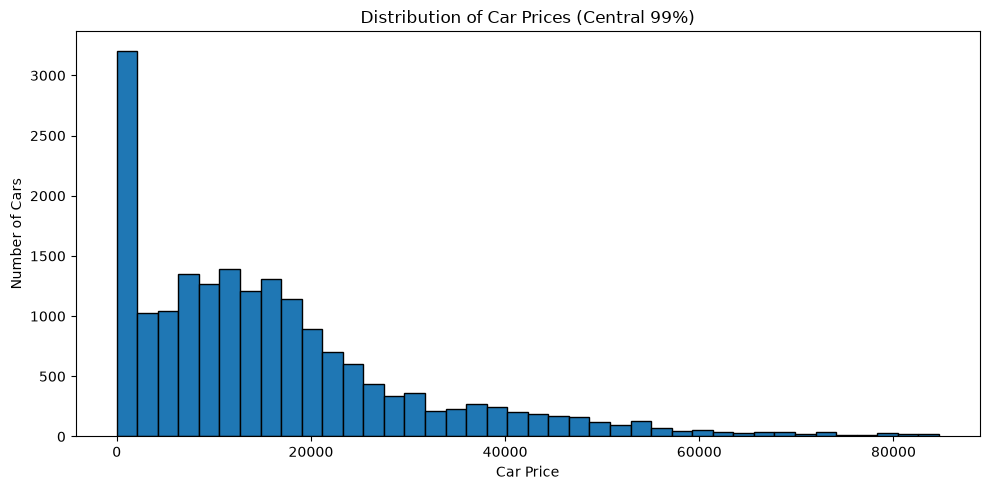

In [17]:

import matplotlib.pyplot as plt

# Keep positive prices for plotting
prices = df.loc[df["Price"] > 0, "Price"]

# Use the 99th percentile as the viewing limit
upper_limit = prices.quantile(0.99)
prices_to_plot = prices[prices <= upper_limit]

plt.figure(figsize=(10, 5))
plt.hist(prices_to_plot, bins=40, edgecolor="black")

plt.xlabel("Car Price")
plt.ylabel("Number of Cars")
plt.title("Distribution of Car Prices (Central 99%)")
plt.tight_layout()
plt.show()


 The car price distribution contains extreme values that require further investigation. These values should not be removed from the dataset without checking whether they are genuine or incorrect records.  

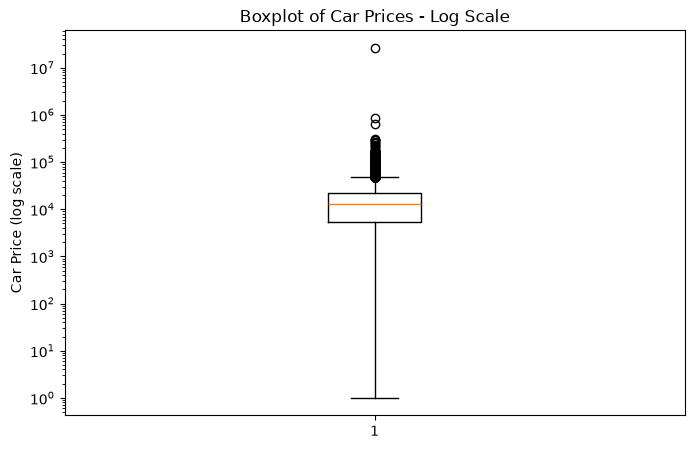

In [19]:

plt.figure(figsize=(8, 5))

plt.boxplot(df["Price"])

plt.yscale("log")
plt.ylabel("Car Price (log scale)")
plt.title("Boxplot of Car Prices - Log Scale")

plt.show()

observation:The boxplot helps visualize the spread and median of car prices.

Points beyond the whiskers indicate potential outliers.

Extremely high prices can make the central box appear compressed.

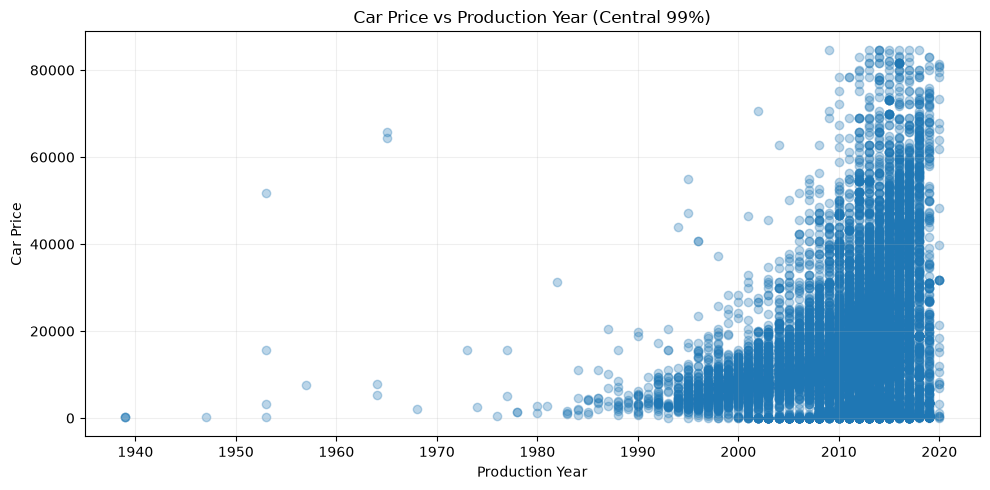

In [24]:

import matplotlib.pyplot as plt

# Limit prices for visualization only
upper_limit = df["Price"].quantile(0.99)
plot_df = df[df["Price"] <= upper_limit]

plt.figure(figsize=(10, 5))

plt.scatter(
    plot_df["Prod. year"],
    plot_df["Price"],
    alpha=0.3
)

plt.xlabel("Production Year")
plt.ylabel("Car Price")
plt.title("Car Price vs Production Year (Central 99%)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Observation:** The graph indicates a positive relationship between production year and car price. In general, newer cars tend to have higher prices. However, prices vary among cars from the same production year, so other features are also important for price prediction.

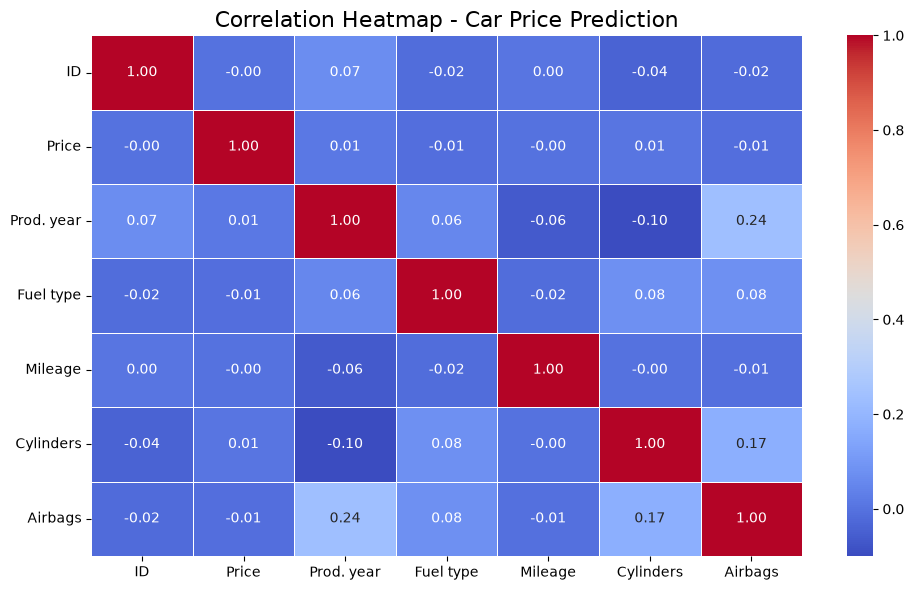

In [27]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlations
correlation = numeric_df.corr()

# Draw heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Car Price Prediction", fontsize=16)
plt.tight_layout()
plt.show()


In [31]:
# Correlation of numerical variables with Price
price_correlation = df.select_dtypes(include="number").corr()["Price"]

# Sort correlations
price_correlation = price_correlation.sort_values(
    ascending=False
)

print("Correlation of Variables with Car Price:")
display(price_correlation)


Correlation of Variables with Car Price:


Price         1.000000
Prod. year    0.012689
Cylinders     0.007435
ID           -0.000797
Mileage      -0.001763
Fuel type    -0.012476
Airbags      -0.012709
Name: Price, dtype: float64

**Step 3: Model Development**

•	Split dataset into train and test sets.

define x and y 

In [30]:
x=df.drop(columns=["Price","ID"])
y=df[["Price"]]
display(x.head())
display(y.head())

,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,1399,LEXUS,RX 450,2010,Jeep,Yes,2,3.5,186005.0,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,1018,CHEVROLET,Equinox,2011,Jeep,No,5,3,192000.0,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,-,HONDA,FIT,2006,Hatchback,No,5,1.3,200000.0,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,862,FORD,Escape,2011,Jeep,Yes,2,2.5,168966.0,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,446,HONDA,FIT,2014,Hatchback,Yes,5,1.3,91901.0,4.0,Automatic,Front,04-May,Left wheel,Silver,4


,Price
0,13328
1,16621
2,8467
3,3607
4,11726


In [32]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=42)

In [34]:
print(xtrain.shape,xtest.shape)

(15139, 16) (3785, 16)


In [35]:
print(ytrain.shape,ytest.shape)

(15139, 1) (3785, 1)


In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

# Identify numerical and categorical columns
numeric_columns = xtrain.select_dtypes(include="number").columns
categorical_columns = xtrain.select_dtypes(exclude="number").columns

# Preprocess numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_columns),
    ("cat", categorical_transformer, categorical_columns)
])

# Build the Linear Regression model
model1 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Linear Regression Model Created Successfully!")


Linear Regression Model Created Successfully!


In [45]:
# Train the Linear Regression model
model1.fit(xtrain, ytrain)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [47]:

# Predict car prices on test data
y_pred = model1.predict(xtest)

# Display actual and predicted prices
results = pd.DataFrame({
    "Actual Price": np.asarray(ytest).reshape(-1),
    "Predicted Price": np.asarray(y_pred).reshape(-1)
})

print("Actual vs Predicted Car Prices:")
display(results.head(10))


Actual vs Predicted Car Prices:


,Actual Price,Predicted Price
0,11604,18931.558547
1,470,18931.157019
2,20162,18932.915941
3,7527,18931.768968
4,18817,18932.126920
5,44003,18932.834350
6,21326,18932.095202
7,15681,18932.693841
8,6899,18931.457064
9,1333,18933.033124


***step 4 :Module Evalution***

In [51]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

# Calculate evaluation metrics
r2 = r2_score(ytest, y_pred)
mae = mean_absolute_error(ytest, y_pred)
mse = mean_squared_error(ytest, y_pred)
rmse = np.sqrt(mse)

# Display results
print("Model Evaluation Results")
print("------------------------")
print("R² Score:", r2)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)


Model Evaluation Results
------------------------
R² Score: -0.008072526466025742
Mean Absolute Error (MAE): 12779.513339495876
Mean Squared Error (MSE): 349023144.079897
Root Mean Squared Error (RMSE): 18682.161119096927


**Observation :**

- A higher R² Score generally indicates a better fit.
- Lower MAE indicates smaller average absolute prediction errors.
- Lower MSE indicates smaller average squared errors.
- Lower RMSE indicates smaller prediction errors in the original price units.

## Step 5: Final Deliverables

# Car Price Prediction Using Linear Regression

## 1. Problem Statement

The objective of this project is to develop a Machine Learning model that predicts the selling price of cars based on their features. Used car dealerships and buyers can use this system to estimate car resale values and make better decisions.

## 2. Dataset Description

The dataset contains information about cars, including their manufacturer, model, production year, category, fuel type, engine volume, mileage, cylinders, gearbox type, and other features.

- **Target Column:** Price
- **Independent Variables:** Car features used to predict the selling price.
- **Dataset Size:** 19,237 rows and 18 columns.

## Data Preprocessing

The following preprocessing steps were performed on the car price dataset:

1. **Load the Dataset:** Loaded the dataset using the Pandas library.
2. **Explore the Dataset:** Checked the dataset shape, column names, and data types.
3. **Check Missing Values:** Checked all columns for missing values.
4. **Convert Mileage:** Removed the `km` text and converted mileage into numerical format.
5. **Convert Fuel Type:** Used Label Encoding to convert fuel type categories into numerical values.
6. **Convert Airbags:** Converted the Airbags column into numerical format.
7. **Handle Remaining Features:** Used imputation and One-Hot Encoding for remaining categorical features before training the model.
8. **Split the Dataset:** Divided the dataset into 80% training data and 20% testing data.

## Key Insights from Exploratory Data Analysis (EDA)

1. **Car Price Distribution:** The histogram shows the distribution of selling prices across the dataset.
2. **Mileage vs Price:** The scatter plot helps examine the relationship between car mileage and selling price.
3. **Price Outliers:** The boxplot helps identify potential outliers and variation in car prices.
4. **Correlation Analysis:** The correlation heatmap shows the relationships between numerical variables and car price.
5. **Feature Relationships:** The correlation values help identify which numerical features have stronger positive or negative linear relationships with the target variable.

## Linear Regression Model

Linear Regression is a supervised Machine Learning algorithm used to predict continuous numerical values. In this project, it is used to predict car selling prices based on car features.

### Model Development Steps

1. **Select Features:** Used car features as independent variables and `Price` as the target variable.
2. **Split Dataset:** Divided the dataset into 80% training data and 20% testing data.
3. **Preprocess Features:** Handled missing values and converted categorical features into numerical format.
4. **Train the Model:** Trained the Linear Regression model using the training dataset.
5. **Make Predictions:** Used the trained model to predict prices for the test dataset.

### Model Objective

The objective is to learn the relationship between car features and selling price so that the model can estimate prices for unseen cars.

## Model Evaluation

The performance of the Linear Regression model was evaluated using the test dataset.

The following evaluation metrics were calculated:

1. **R² Score:** Measures how well the model explains the variation in car prices.
2. **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted car prices.
3. **Mean Squared Error (MSE):** Measures the average squared difference between actual and predicted car prices.
4. **Root Mean Squared Error (RMSE):** Measures the prediction error in the same units as car prices.

### Evaluation Results

- R² Score: [Enter your actual result]
- MAE: [Enter your actual result]
- MSE: [Enter your actual result]
- RMSE: [Enter your actual result]

## Conclusion

In this project, a Linear Regression model was developed to predict car selling prices using car features. The project included data understanding, preprocessing, exploratory data analysis, model development, and evaluation.

The model was evaluated using R² Score, Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE).

The evaluation results help determine how well the model predicts car prices. Possible improvements can be identified based on the model's performance and prediction errors.